# Spiking Expected SARSA: 120-second / 2,250 m comparison

Compare four freshly trained agents using the **long route**: 2,250 m with a
120 s deadline. Episodes end earlier on a crash or route completion. This is a
small multi-seed experiment, not a convergence study.

1. **Linear Expected SARSA**: existing normalized semi-gradient baseline.
2. **SNN fixed reservoir**: fixed spiking feature extractor; train a signed linear Q readout.
3. **SNN surrogate**: train hidden synapses and Q readout with surrogate semi-gradients.
4. **SNN TD-STDP hybrid**: heuristic TD-modulated pair-STDP in the hidden layer;
   train the Q readout with semi-gradient TD. This is **not pure STDP**, nor a claim
   that pair-STDP equals the Expected SARSA gradient.

All agents share observation features, 20 joint driving/sensing actions, reward,
discount, exploration endpoints, episode budget, and held-out test conditions.
Different policies can terminate at different times, so equal episodes do not
imply equal environment steps or computation. Training and evaluation measure
**modeled sensor energy only**, not the energy consumed by this SNN simulation.

Run top to bottom using the **MORL4VSO (.venv)** kernel. Dependencies:
`../.venv/bin/python -m pip install -r ../requirements-dqn.txt` from this directory.
The complete study saves each model/history and caches finished evaluations;
rerunning reuses matching artifacts. Change `STUDY_NAME` or settings for a new study.

Run All reads the bundled results. Set `RUN_TRAINING = True` to train fresh models.

In [1]:
from pathlib import Path
import os, sys, json, copy, time, hashlib, platform
from dataclasses import asdict
from datetime import datetime
from zoneinfo import ZoneInfo
from importlib.metadata import version
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
os.environ.setdefault("PYGAME_HIDE_SUPPORT_PROMPT", "1")
os.environ.setdefault("MPLBACKEND", "Agg")
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "algorithms/snn.py").exists()
                     and (p / "environments/sensor_highway/env.py").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook inside final_project.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from algorithms.sensor_agent import AgentSettings, LinearExpectedSarsa, ObservationEncoder
from algorithms.snn import SNNSettings, SpikingExpectedSarsa
from environments.sensor_highway import ExperimentConfig, SensorHighwayEnv
from experiments.agent_helpers import train_agent, evaluate_agents
from experiments.snn_helpers import train_snn
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
print("Interpreter:", sys.executable)
print("PyTorch:", torch.__version__, "| device: CPU | threads:", torch.get_num_threads())

Interpreter: /Users/zac/Desktop/Reinforcment_Learning/final_project/.venv/bin/python
PyTorch: 2.15.0 | device: CPU | threads: 1


## Matched long-route protocol

Use three independent training seeds, **60 episodes per agent per seed**, and
four held-out traffic seeds in each of clear, rain, and fog (12 test trips per
trained model). Training weather is randomized. Traffic seeds are paired across
agents at each episode, but actions change subsequent trajectories.

The long task and its reward coefficients match the existing 120 s / 2,250 m
notebook. The 60-episode budget here is smaller than that notebook's 200 episodes;
it is shared by all four agents. Increase `TRAIN_EPISODES` for a longer study.
Gamma 0.95 matches the original SARSA setting; it is a per-decision discount,
so late completion rewards are strongly discounted on this longer horizon.

In [2]:
STUDY_NAME = "snn_expected_sarsa_120s_60ep_3seeds_v1"
TRAIN_EPISODES = 60
TRAIN_SEEDS = [42, 1042, 2042]
TEST_SEEDS = list(range(100_000, 100_004))
TEST_WEATHER = ["clear", "rain", "fog"]
POLICIES = {"linear": "Linear Expected SARSA", "reservoir": "SNN fixed reservoir",
            "surrogate": "SNN surrogate", "td_stdp": "SNN TD-STDP hybrid"}
config = ExperimentConfig()
config.highway.update(duration=120, high_speed_reward=0.0, collision_reward=-10.0)
config.weather.preset = "random"
config.weather.severity = 0.7
config.reward.route_distance_m = 2250
config.validate()
snn_settings = SNNSettings(episodes=TRAIN_EPISODES)
linear_settings = AgentSettings(episodes=TRAIN_EPISODES, alpha=0.12,
                               gamma=snn_settings.gamma,
                               epsilon_start=snn_settings.epsilon_start,
                               epsilon_end=snn_settings.epsilon_end)
for seed in TRAIN_SEEDS:
    assert not set(TEST_SEEDS).intersection(range(seed, seed + TRAIN_EPISODES))
assert config.highway["duration"] == 120 and config.reward.route_distance_m == 2250
RUN_TRAINING = False  # Set True to train a fresh control study in runs/local.
RECORDED = PROJECT_ROOT / "runs/exploratory" / STUDY_NAME
OUTPUT = PROJECT_ROOT / "runs/local" / ("snn_expected_sarsa_120s" if RUN_TRAINING else "snn_review")
OUTPUT.mkdir(parents=True, exist_ok=True)
source_paths = ["algorithms/snn.py", "algorithms/sensor_agent.py", "experiments/snn_helpers.py",
                "experiments/agent_helpers.py", "experiments/notebook_helpers.py"]
source_paths += [str(p.relative_to(PROJECT_ROOT)) for p in sorted((PROJECT_ROOT / "environments/sensor_highway").glob("*.py"))]
source_hashes = {p: hashlib.sha256((PROJECT_ROOT/p).read_bytes()).hexdigest() for p in source_paths}
protocol = {"study": STUDY_NAME, "config": asdict(config), "snn_settings": asdict(snn_settings),
            "linear_settings": asdict(linear_settings), "train_seeds": TRAIN_SEEDS,
            "test_seeds": TEST_SEEDS, "test_weather": TEST_WEATHER,
            "sources_sha256": source_hashes,
            "versions": {p: version(p) for p in ["torch", "numpy", "pandas", "matplotlib", "highway-env", "gymnasium"]}}
protocol_hash = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()
metadata_path = OUTPUT / "metadata.json"
if RUN_TRAINING and metadata_path.exists():
    metadata = json.loads(metadata_path.read_text())
    if metadata["protocol_hash"] != protocol_hash:
        raise RuntimeError("Protocol or implementation changed. Use a new STUDY_NAME to preserve prior results.")
else:
    metadata = {**protocol, "protocol_hash": protocol_hash,
                "started_at": datetime.now(ZoneInfo("America/New_York")).isoformat(),
                "python": sys.version, "platform": platform.platform(),
                "checkpoint_kind": "evaluation policy, not optimizer resume state"}
    metadata_path.write_text(json.dumps(metadata, indent=2) + "\n")
config.save(OUTPUT / "config.json")
display(pd.Series({"route_m": config.reward.route_distance_m, "deadline_s": config.highway["duration"],
                   "episodes_per_model": TRAIN_EPISODES, "trained_models": len(POLICIES)*len(TRAIN_SEEDS),
                   "test_trips_per_model": len(TEST_SEEDS)*len(TEST_WEATHER), "output": str(OUTPUT)}))
display(pd.Series(asdict(snn_settings), name="SNN settings"))

route_m                                                              2250
deadline_s                                                            120
episodes_per_model                                                     60
trained_models                                                         12
test_trips_per_model                                                   12
output                  /Users/zac/Desktop/Reinforcment_Learning/final...
dtype: object

episodes              60.000
learning_rate          0.001
gamma                  0.950
epsilon_start          1.000
epsilon_end            0.100
hidden_size           64.000
simulation_steps      16.000
membrane_decay         0.900
threshold              1.000
surrogate_slope        5.000
gradient_clip         10.000
stdp_learning_rate     0.001
trace_decay            0.800
stdp_depression        1.050
td_modulation_clip     5.000
weight_bound           1.000
Name: SNN settings, dtype: float64

## What is learned

The existing observation vector is split into positive and negative channels.
A deterministic integrate-and-fire encoder produces input spikes over 16 internal
steps; 64 leaky integrate-and-fire neurons produce mean firing rates. A signed
linear readout outputs 20 Q estimates. Membranes reset **for each observation**;
this experiment adds nonlinear spiking features, not memory across driving decisions.
The internal 16-step window does not advance the highway simulation by 16 steps.

Every actual environment step uses the same Expected SARSA target:

$$y=r+\gamma[(1-\epsilon)\max_{a'}Q(s',a')+\epsilon\operatorname{mean}_{a'}Q(s',a')].$$

Terminal transitions, including a missed finite-route deadline, use $y=r$.
Surrogate learning minimizes $\frac12(\operatorname{stopgrad}(y)-Q(s,a))^2$.
There is no replay buffer or separate target network.

In the hybrid, strictly earlier pre/post spike pairs build a local eligibility
matrix during the **current observation only**. Hidden weights receive
$\Delta W=\eta_{STDP}\operatorname{clip}(\delta)E$, followed by weight bounds.
The signed TD error modulates the local rule globally; it does not solve hidden
synapse credit assignment exactly. The readout still uses semi-gradient TD.
Next-state spikes do not contribute to the current eligibility. These within-window
traces are not multi-decision SARSA($\lambda$) traces.

References: [spiking SARSA model (2015)](https://pmc.ncbi.nlm.nih.gov/articles/PMC4347982/),
[TD-STDP Q-learning controller (2023)](https://www.mdpi.com/2079-9292/12/2/310),
[surrogate gradients (2019)](https://arxiv.org/abs/1901.09948), and
[dopamine-modulated STDP (2007)](https://pubmed.ncbi.nlm.nih.gov/17220510/).

In [3]:
# Preflight: long-route schema, signed Q outputs, terminal target, and frozen inference.
with SensorHighwayEnv(config) as env:
    obs, _ = env.reset(seed=TRAIN_SEEDS[0])
encoder = ObservationEncoder(config)
features = encoder(obs)
probe = SpikingExpectedSarsa(len(features), snn_settings, feature_schema=encoder.feature_schema)
assert probe.values(features).shape == (20,)
assert float(probe.td_target(-10, None, True, 0.2)) == -10
with torch.no_grad():
    q, rates, eligibility = probe.network(probe._features(features), collect_stdp=True)
print(f"Features: {len(features)}; actions: {len(probe.actions)}; initial hidden spike rate: {rates.mean():.3f}")
print("Preflight passed; 120 s / 2,250 m configuration verified.")

Features: 112; actions: 20; initial hidden spike rate: 0.262
Preflight passed; 120 s / 2,250 m configuration verified.


## Train fresh policies and evaluate held-out trips

Each completed model, training history, and runtime is saved immediately.
Evaluation calls the existing frozen policy helper. A checkpoint round trip must
reproduce Q predictions exactly before the evaluation is accepted. Weight tensors
and update counters are checked again after evaluation to detect accidental learning.
No test feedback is used to choose hyperparameters.

In [4]:
if not RUN_TRAINING:
    training = pd.read_csv(RECORDED / "training.csv")
    evaluation = pd.read_csv(RECORDED / "evaluation.csv")
    runtimes = pd.read_csv(RECORDED / "runtime.csv")
    print("Loaded recorded training and held-out results:", RECORDED.relative_to(PROJECT_ROOT))
else:
    histories, evaluations, runtime_records = [], [], []
    study_start = time.perf_counter()
    for training_seed in TRAIN_SEEDS:
        for policy_id, label in POLICIES.items():
            run_dir = OUTPUT / f"{policy_id}_seed{training_seed}"
            run_dir.mkdir(exist_ok=True)
            model_path = run_dir / ("agent.npz" if policy_id == "linear" else "agent.pt")
            history_path, runtime_path = run_dir / "training.csv", run_dir / "runtime.json"
            eval_path = run_dir / "evaluation.csv"
            print(f"\n{label} | training seed {training_seed}", flush=True)
            if model_path.exists() and history_path.exists() and runtime_path.exists():
                agent = (LinearExpectedSarsa.load(model_path) if policy_id == "linear"
                         else SpikingExpectedSarsa.load(model_path))
                history = pd.read_csv(history_path)
                runtime = json.loads(runtime_path.read_text())
                print("Loaded completed training", flush=True)
            else:
                started = time.perf_counter()
                if policy_id == "linear":
                    agent, history = train_agent(config, linear_settings, seed=training_seed)
                else:
                    agent, history = train_snn(config, snn_settings, seed=training_seed, learning_rule=policy_id)
                training_s = time.perf_counter() - started
                agent.save(model_path)
                history.to_csv(history_path, index=False)
                runtime = {"training_wall_s": training_s, "environment_steps": int(history.steps.sum()),
                           "episodes": len(history), "parameters": int(agent.weights.size) if policy_id == "linear"
                           else sum(p.numel() for p in agent.network.parameters()),
                           "trainable_by_gradient": int(agent.weights.size) if policy_id == "linear"
                           else sum(p.numel() for p in agent.network.parameters() if p.requires_grad)}
                runtime_path.write_text(json.dumps(runtime, indent=2) + "\n")
            restored = (LinearExpectedSarsa.load(model_path) if policy_id == "linear"
                        else SpikingExpectedSarsa.load(model_path))
            np.testing.assert_array_equal(agent.values(features), restored.values(features))
            history = history.assign(policy=label, policy_id=policy_id, training_seed=training_seed)
            histories.append(history)
            if eval_path.exists():
                evaluation = pd.read_csv(eval_path)
                print("Loaded completed evaluation", flush=True)
            else:
                before = (agent.weights.copy() if policy_id == "linear" else
                          {k: v.clone() for k, v in agent.network.state_dict().items()})
                updates_before = getattr(agent, "q_updates", None)
                started = time.perf_counter()
                evaluation = evaluate_agents(config, {label: agent}, TEST_SEEDS, TEST_WEATHER)
                runtime["evaluation_wall_s"] = time.perf_counter() - started
                if policy_id == "linear":
                    np.testing.assert_array_equal(before, agent.weights)
                else:
                    for k, v in agent.network.state_dict().items():
                        torch.testing.assert_close(before[k], v, rtol=0, atol=0)
                    assert agent.q_updates == updates_before
                evaluation = evaluation.assign(policy_id=policy_id, training_seed=training_seed)
                evaluation.to_csv(eval_path, index=False)
                runtime_path.write_text(json.dumps(runtime, indent=2) + "\n")
            evaluations.append(evaluation)
            runtime_records.append({"policy": label, "training_seed": training_seed, **runtime})
            print(f"Saved {len(history)} training episodes; {len(evaluation)} test trips. "
                  f"Study elapsed: {time.perf_counter()-study_start:.1f}s", flush=True)
    training = pd.concat(histories, ignore_index=True)
    evaluation = pd.concat(evaluations, ignore_index=True)
    runtimes = pd.DataFrame(runtime_records)
    assert len(training) == TRAIN_EPISODES * len(TRAIN_SEEDS) * len(POLICIES)
    assert len(evaluation) == len(TEST_SEEDS)*len(TEST_WEATHER)*len(TRAIN_SEEDS)*len(POLICIES)
    training.to_csv(OUTPUT / "training.csv", index=False)
    evaluation.to_csv(OUTPUT / "evaluation.csv", index=False)
    runtimes.to_csv(OUTPUT / "runtime.csv", index=False)
    print("All training and held-out evaluations complete.")


Linear Expected SARSA | training seed 42


off+front+radar_rgb+all_on: episode 20/60, return=-15.15, epsilon=0.71


off+front+radar_rgb+all_on: episode 40/60, return=-14.18, epsilon=0.41


off+front+radar_rgb+all_on: episode 60/60, return=31.26, epsilon=0.10


Evaluated clear


Evaluated rain


... (96 outputs left out)

Evaluated rain


Evaluated fog


Saved 60 training episodes; 12 test trips. Study elapsed: 1045.7s


All training and held-out evaluations complete.


## Results across independent training seeds

First aggregate the 12 test trips for each trained model, then summarize across
training seeds. `completion_sd` is the sample SD across three trained models,
not a confidence interval. Test trips share scenario seeds and are not independent
replicates of training. Completion time is conditional on success; power and
energy cover all trips. Low trip energy can also result from an early crash.
Compare completion and crashes alongside energy rather than ranking by energy alone.

Some training seeds ran concurrently. Recorded wall times are descriptive, not a controlled speed benchmark.

In [5]:
per_seed = evaluation.groupby(["policy", "training_seed"], sort=False).agg(
    test_trips=("completed", "size"), completion_rate=("completed", "mean"),
    crash_rate=("crashed", "mean"), mean_return=("return", "mean"),
    mean_power_w=("mean_power_w", "mean"), mean_energy_j=("energy_j", "mean"),
    successful_completion_s=("completion_time_s", "mean"), mean_distance_m=("distance_m", "mean"))
summary = per_seed.groupby("policy", sort=False).agg(
    training_seeds=("completion_rate", "size"), completion_mean=("completion_rate", "mean"),
    completion_sd=("completion_rate", "std"), crash_mean=("crash_rate", "mean"),
    return_mean=("mean_return", "mean"), mean_power_w=("mean_power_w", "mean"),
    mean_energy_j=("mean_energy_j", "mean"))
# Pool successful trips directly so models with different success counts are not equally weighted here.
summary["successful_completion_s"] = evaluation.groupby("policy")["completion_time_s"].mean()
weather_summary = evaluation.groupby(["policy", "weather"], sort=False).agg(
    test_trips=("completed", "size"), completion_rate=("completed", "mean"),
    crash_rate=("crashed", "mean"), mean_power_w=("mean_power_w", "mean"))
per_seed.to_csv(OUTPUT / "per_training_seed.csv")
summary.to_csv(OUTPUT / "summary.csv")
weather_summary.to_csv(OUTPUT / "weather_summary.csv")
display(summary.round(3))
display(per_seed.round(3))
display(weather_summary.round(3))
display(runtimes.groupby("policy", sort=False)[["environment_steps", "training_wall_s", "evaluation_wall_s", "parameters"]].mean().round(2))

,training_seeds,completion_mean,completion_sd,crash_mean,return_mean,mean_power_w,mean_energy_j,successful_completion_s
policy,,,,,,,,
Linear Expected SARSA,3,0.667,0.577,0.333,16.158,1.800,141.600,112.500
SNN fixed reservoir,3,0.444,0.509,0.556,3.565,66.531,2022.768,110.812
SNN surrogate,3,0.333,0.577,0.667,-1.009,7.335,109.750,112.500
SNN TD-STDP hybrid,3,0.139,0.241,0.861,-11.698,65.212,1577.583,110.800


,,test_trips,completion_rate,crash_rate,mean_return,mean_power_w,mean_energy_j,successful_completion_s,mean_distance_m
policy,training_seed,,,,,,,,
Linear Expected SARSA,42,12,0.000,1.000,-16.745,1.800,19.800,NaN,273.720
SNN fixed reservoir,42,12,1.000,0.000,30.082,27.198,3052.792,112.25,2255.103
SNN surrogate,42,12,0.000,1.000,-17.836,1.800,10.125,NaN,164.962
SNN TD-STDP hybrid,42,12,0.000,1.000,-18.174,64.837,363.763,NaN,164.962
Linear Expected SARSA,1042,12,1.000,0.000,32.610,1.800,202.500,112.50,2253.000
SNN fixed reservoir,1042,12,0.000,1.000,-18.026,121.804,1359.063,NaN,275.663
SNN surrogate,1042,12,0.000,1.000,-17.800,18.404,116.625,NaN,178.603
SNN TD-STDP hybrid,1042,12,0.000,1.000,-18.078,52.163,299.779,NaN,168.462
Linear Expected SARSA,2042,12,1.000,0.000,32.610,1.800,202.500,112.50,2253.000


test_trips  completion_rate  crash_rate  \
policy                weather                                            
Linear Expected SARSA clear            12            0.667       0.333   
                      rain             12            0.667       0.333   
                      fog              12            0.667       0.333   
SNN fixed reservoir   clear            12            0.333       0.667   
                      rain             12            0.417       0.583   
                      fog              12            0.583       0.417   
SNN surrogate         clear            12            0.333       0.667   
                      rain             12            0.333       0.667   
                      fog              12            0.333       0.667   
SNN TD-STDP hybrid    clear            12            0.083       0.917   
                      rain             12            0.083       0.917   
                      fog              12            0.250       0.750   

                               mean_power_w  
policy                weather                
Linear Expected SARSA clear           1.800  
                      rain            1.800  
                      fog             1.800  
SNN fixed reservoir   clear          68.879  
                      rain           67.737  
                      fog            62.977  
SNN surrogate         clear           6.953  
                      rain            7.548  
                      fog             7.502  
SNN TD-STDP hybrid    clear          63.586  
                      rain           67.627  
                      fog            64.422

,environment_steps,training_wall_s,evaluation_wall_s,parameters
policy,,,,
Linear Expected SARSA,2879.67,112.41,62.82,2240.0
SNN fixed reservoir,2041.67,86.67,50.86,15700.0
SNN surrogate,1615.33,68.71,33.50,15700.0
SNN TD-STDP hybrid,2021.33,89.26,24.89,15700.0


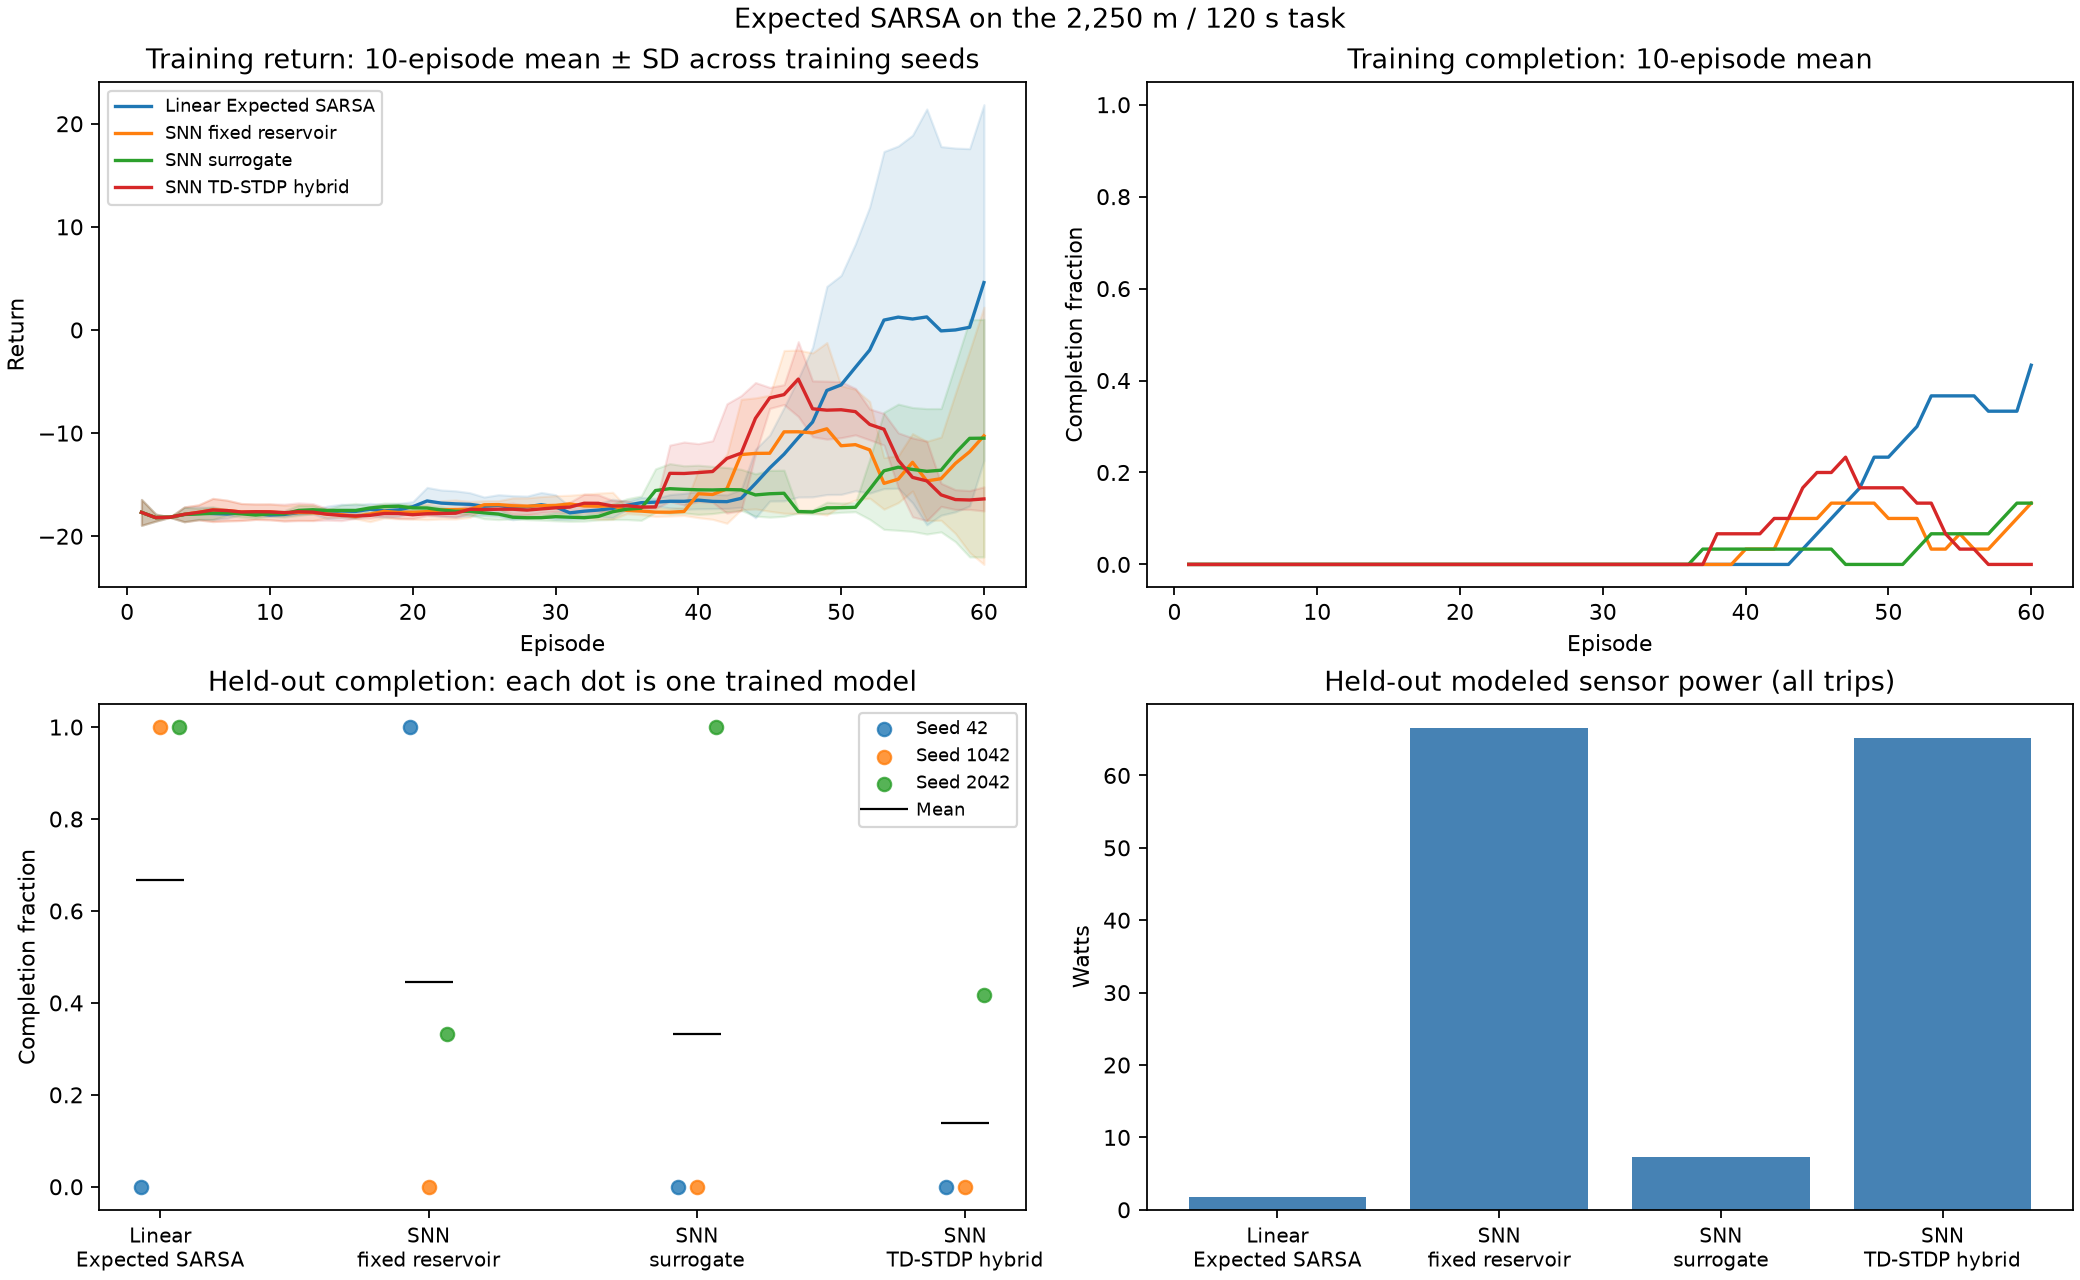

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
for label in POLICIES.values():
    group = training[training.policy == label]
    curves = group.pivot(index="episode", columns="training_seed", values="return").rolling(10, min_periods=1).mean()
    mean, sd = curves.mean(axis=1), curves.std(axis=1)
    line, = axes[0, 0].plot(mean.index, mean, label=label)
    axes[0, 0].fill_between(mean.index, mean-sd, mean+sd, alpha=.12, color=line.get_color())
    completes = group.pivot(index="episode", columns="training_seed", values="route_completed").rolling(10, min_periods=1).mean()
    axes[0, 1].plot(completes.index, completes.mean(axis=1), label=label)
labels = list(POLICIES.values())
x = np.arange(len(labels))
for seed_index, training_seed in enumerate(TRAIN_SEEDS):
    points = per_seed.xs(training_seed, level="training_seed").reindex(labels)
    axes[1, 0].scatter(x + (seed_index-1)*0.07, points.completion_rate,
                       alpha=.8, label=f"Seed {training_seed}")
axes[1, 0].plot(x, summary.loc[labels, "completion_mean"], "k_", markersize=22, label="Mean")
axes[1, 1].bar(x, summary.loc[labels, "mean_power_w"], color="steelblue")
for ax in axes[1]:
    ax.set_xticks(x, [s.replace(" ", "\n", 1) for s in labels], fontsize=9)
axes[0, 0].set(title="Training return: 10-episode mean ± SD across training seeds", xlabel="Episode", ylabel="Return")
axes[0, 1].set(title="Training completion: 10-episode mean", xlabel="Episode", ylabel="Completion fraction", ylim=(-.05, 1.05))
axes[1, 0].set(title="Held-out completion: each dot is one trained model", ylabel="Completion fraction", ylim=(-.05, 1.05))
axes[1, 1].set(title="Held-out modeled sensor power (all trips)", ylabel="Watts")
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
fig.suptitle("Expected SARSA on the 2,250 m / 120 s task")
fig.savefig(OUTPUT / "comparison.png", dpi=160)
display(fig)
plt.close(fig)

## Spiking activity, sensing decisions, and limitations

Hidden spike rate is spikes per hidden neuron per internal simulation step.
A high silent fraction can indicate inactive features; rates near one can indicate
saturation. Neither metric directly measures electrical power. The fixed reservoir
and TD-STDP hybrid train only the readout by gradient; the latter also updates
hidden weights using its separate local plasticity rule.

This experiment uses pooled observation features, not raw event-camera spikes.
No neuromorphic hardware is involved. Differences from linear SARSA include the
representation, parameter count, and optimizer. A matched nonspiking nonlinear
Expected SARSA control would be needed to isolate the value of spiking itself.
There are only three training seeds, no hyperparameter search, and no convergence
claim. All 60-episode results should be interpreted as exploratory.

,,hidden_spike_rate,silent_hidden_fraction,mean_abs_eligibility,mean_abs_td
policy,training_seed,,,,
SNN fixed reservoir,42,0.2862,0.3223,0.0000,1.4249
SNN surrogate,42,0.2031,0.5267,0.0000,1.7911
SNN TD-STDP hybrid,42,0.2861,0.3216,0.0139,1.5086
SNN fixed reservoir,1042,0.2767,0.3386,0.0000,1.5984
SNN surrogate,1042,0.1376,0.6477,0.0000,1.6104
SNN TD-STDP hybrid,1042,0.2550,0.3555,0.0121,1.5940
SNN fixed reservoir,2042,0.2435,0.4035,0.0000,1.4615
SNN surrogate,2042,0.1699,0.6205,0.0000,1.8182
SNN TD-STDP hybrid,2042,0.2345,0.4197,0.0110,1.3502


,mode_fraction_off,mode_fraction_front,mode_fraction_radar_rgb,mode_fraction_all_on
policy,,,,
Linear Expected SARSA,1.000,0.000,0.000,0.000
SNN fixed reservoir,0.009,0.461,0.188,0.342
SNN surrogate,0.733,0.267,0.000,0.000
SNN TD-STDP hybrid,0.260,0.120,0.295,0.325


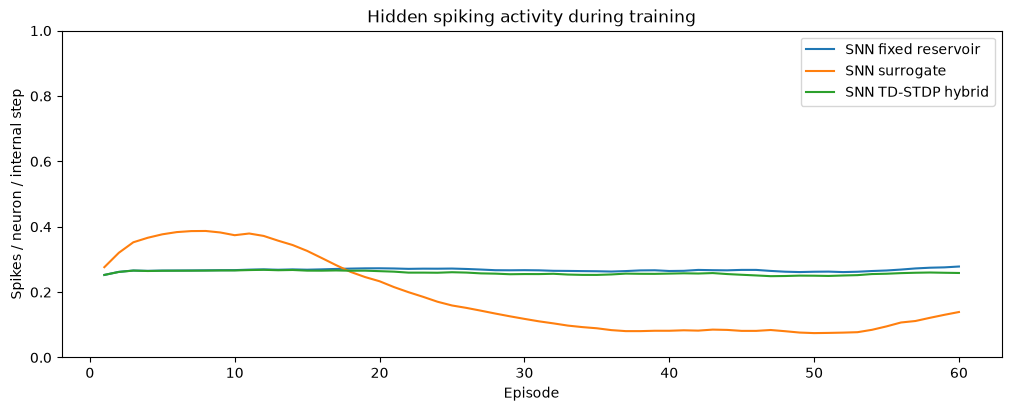

In [7]:
spiking = training[training.policy_id != "linear"]
activity = spiking.groupby(["policy", "training_seed"], sort=False).agg(
    hidden_spike_rate=("hidden_spike_rate", "mean"),
    silent_hidden_fraction=("silent_hidden_fraction", "mean"),
    mean_abs_eligibility=("mean_abs_eligibility", "mean"), mean_abs_td=("mean_abs_td", "mean"))
activity.to_csv(OUTPUT / "spiking_diagnostics.csv")
display(activity.round(4))
sensing = evaluation.groupby("policy", sort=False)[[c for c in evaluation if c.startswith("mode_fraction_")]].mean()
sensing.to_csv(OUTPUT / "sensing_fractions.csv")
display(sensing.round(3))
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for label, group in spiking.groupby("policy", sort=False):
    rates = group.groupby("episode").hidden_spike_rate.mean().rolling(10, min_periods=1).mean()
    ax.plot(rates.index, rates, label=label)
ax.set(title="Hidden spiking activity during training", xlabel="Episode", ylabel="Spikes / neuron / internal step", ylim=(0, 1))
ax.legend()
fig.savefig(OUTPUT / "spiking_activity.png", dpi=160)
display(fig)
plt.close(fig)

In [8]:
# Save a compact, data-driven report without declaring an overall winner.
lines = ["# Spiking Expected SARSA: long-route experiment", "",
         "Task: 2,250 m route, 120 s deadline. 60 training episodes × 3 seeds per method.",
         "Held-out evaluation: 4 traffic seeds × 3 weather conditions per trained model.", "",
         "| Policy | Completion | Crash | Return | Sensor power (W) | Successful time (s) |",
         "|---|---:|---:|---:|---:|---:|"]
for label, row in summary.iterrows():
    lines.append(f"| {label} | {row.completion_mean:.1%} | {row.crash_mean:.1%} | {row.return_mean:.2f} | {row.mean_power_w:.2f} | {row.successful_completion_s:.2f} |")
lines += ["", "## Interpretation", "",
          "Completion and crash rates describe safety/task success; lower energy alone can reflect early crashes.",
          "The TD-STDP hybrid combines heuristic hidden plasticity with a gradient-trained signed Q readout.",
          "Surrogate learning still uses semi-gradients: the Expected SARSA target is detached.",
          "Only three training seeds were run. Episodes are matched; environment steps and compute are not.",
          "Sensor energy excludes neural inference energy. No neuromorphic energy advantage is measured.",
          "Some training seeds ran concurrently; wall times are not a controlled speed benchmark.",
          "The networks reset each observation and do not add memory across environment decisions.",
          "A nonspiking nonlinear Expected SARSA control and larger seed/budget studies remain future work.", "",
          "Artifacts include all model checkpoints, raw training/evaluation CSVs, source hashes, versions, and plots."]
(OUTPUT / "study_report.md").write_text("\n".join(lines) + "\n")
metadata["completed_at"] = datetime.now(ZoneInfo("America/New_York")).isoformat()
metadata["training_rows"] = len(training)
metadata["evaluation_rows"] = len(evaluation)
metadata_path.write_text(json.dumps(metadata, indent=2) + "\n")
print("Saved report and artifacts:", OUTPUT)
print(f"Verified {len(training)} training episodes and {len(evaluation)} held-out trips.")

Saved report and artifacts: /Users/zac/Desktop/Reinforcment_Learning/final_project/experiments/artifacts/snn_expected_sarsa_120s_60ep_3seeds_v1
Verified 720 training episodes and 144 held-out trips.


## Findings from this executed run

Across 36 held-out trips per method, linear Expected SARSA completed **24/36
(66.7%)**, the fixed-reservoir SNN **16/36 (44.4%)**, the surrogate SNN **12/36
(33.3%)**, and the TD-STDP hybrid **5/36 (13.9%)**. The linear baseline had the
highest completion rate under this protocol. The SNN variants did not improve it.

Results varied strongly with training seed: for example, the fixed reservoir
completed 12/12, 0/12, and 4/12 trips across its three trained models. This
60-episode experiment does not establish convergence or rule out better SNN
settings. Keep the linear baseline when investigating larger budgets, discount
choices for the long horizon, or alternative plasticity rules.